<a href="https://colab.research.google.com/github/yakhyo018/computer_vision/blob/main/Pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [56]:
import torch

In [57]:
print("CUDA available:", torch.cuda.is_available())

CUDA available: True


In [58]:
scalar = torch.tensor(5)  # 0D
print('scalar:', scalar)

scalar: tensor(5)


In [59]:
vector = torch.tensor([1, 2, 3])  # 1D
print("vector:", vector)

vector: tensor([1, 2, 3])


In [60]:
MATRIX = torch.tensor([[1, 2, 3],
                       [4, 5, 6]])  # 2D
print('MATRIX:', MATRIX)

MATRIX: tensor([[1, 2, 3],
        [4, 5, 6]])


In [61]:
tensor3d = torch.stack([MATRIX, MATRIX + 10])
print('tensor3d:', tensor3d)

tensor3d: tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[11, 12, 13],
         [14, 15, 16]]])


In [62]:
random_numbers = torch.rand(2, 3)  # 0 ~ 1
print('Random Numbers:', random_numbers)
print('Data type:', random_numbers.dtype)
print('Device of random_numbers:', random_numbers.device)

Random Numbers: tensor([[0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936]])
Data type: torch.float32
Device of random_numbers: cpu


In [63]:
print('Zeros:', torch.zeros(3, 3))

Zeros: tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]])


In [64]:
print('Ones:', torch.ones(2, 4))

Ones: tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.]])


In [65]:
x = torch.tensor([[1, 2],
                  [3, 4]])
y = torch.tensor([[5, 6],
                  [7, 8]])

# Element-wise addition
print('Addition:', x + y)
print('----------------')

# Element-wise multiplication
print('Multiplication:', x * y)
print('----------------')

# Matrix multiplication
print('Matrix @ multiplication:', x @ y)

#x
[[1, 2],
 [3, 4]]

#y
[[5, 6],
 [7, 8]]

Addition: tensor([[ 6,  8],
        [10, 12]])
----------------
Multiplication: tensor([[ 5, 12],
        [21, 32]])
----------------
Matrix @ multiplication: tensor([[19, 22],
        [43, 50]])


[[5, 6], [7, 8]]

[1, 2] * [5, 7] = 1 * 5 + 2 * 7 = 5 + 14 = 19

[1, 2] * [6, 8] = 1 * 6 + 2 * 8 = 6 + 16 = 22

==========================================================

| Matrix A shape | Matrix B shape | Valid? | Output shape |
|---|---|---|---|
| (2×3) | (3×4) | ✅ | (2×4) |
| (4×5) | (5×2) | ✅ | (4×2) |
| (3×2) | (2×1) | ✅ | (3×1) |
| (2×2) | (2×2) | ✅ | (2×2) |
| (2×3) | (4×2) | ❌ | ❌ Invalid |



In [66]:
# Import PyTorch and matplotlib
import torch
from torch import nn  # nn contains all of PyTorch's building blocks for neural networks | nn module
import matplotlib.pyplot as plt

# Check PyTorch version
torch.__version__

'2.11.0+cu130'

In [67]:
# Setup device diagnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [68]:
# Create weight and bias
weight = 0.7
bias = 0.3

# Create range values
start = 0
end = 1
step = 0.02

# Create X and y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1)  # without unsqueeze, errors will happen later on (shapes within linear layers)
y = weight * X + bias

# Linear Regression: y = wx + b
print("X:", X)

print("\ny:", y)


# Split data
train_split = int(0.8 * len(X)) # 10000 (100%) data => 8000 (80%) train | 2000 (20%) test
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

X: tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])

y: tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
  

(40, 40, 10, 10)

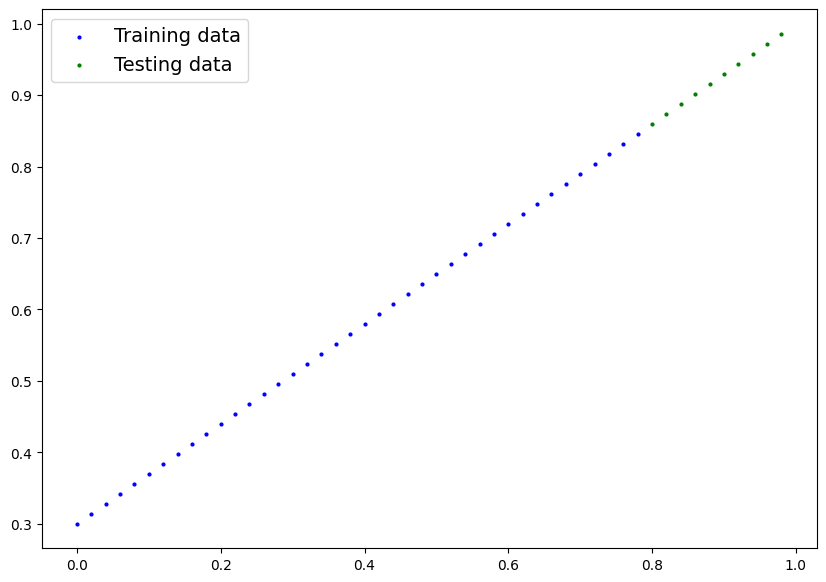

In [69]:
import matplotlib.pyplot as plt

def plot_predictions(train_data=X_train,
                    train_labels=y_train,
                    test_data=X_test,
                    test_labels=y_test,
                    predictions=None):

    plt.figure(figsize=(10, 7))

    # Training data — blue
    plt.scatter(train_data, train_labels, c='b', s=4, label='Training data')

    # Test data — green
    plt.scatter(test_data, test_labels, c='g', s=4, label='Testing data')

    if predictions is not None:
        plt.scatter(test_data, predictions, c='r', s=4, label='Predictions')

    plt.legend(prop={'size': 14})
    plt.show()

plot_predictions()

In [70]:
# Subclass nn.Module to make our model
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()

        # Use nn.Linear() for creating the model parameters
        self.linear_layer = nn.Linear(
            in_features=1,
            out_features=1
        )  # Linear layer: y = w*x + b

    # Define the forward computation
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)


# Set the manual seed
torch.manual_seed(42)

model_1 = LinearRegressionModelV2()
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
             ('linear_layer.bias', tensor([0.8300]))])

In [71]:
# Create loss function
loss_fn = nn.L1Loss()

# Create optimizer
optimizer = torch.optim.SGD(
    params=model_1.parameters(),
    lr=0.01
)

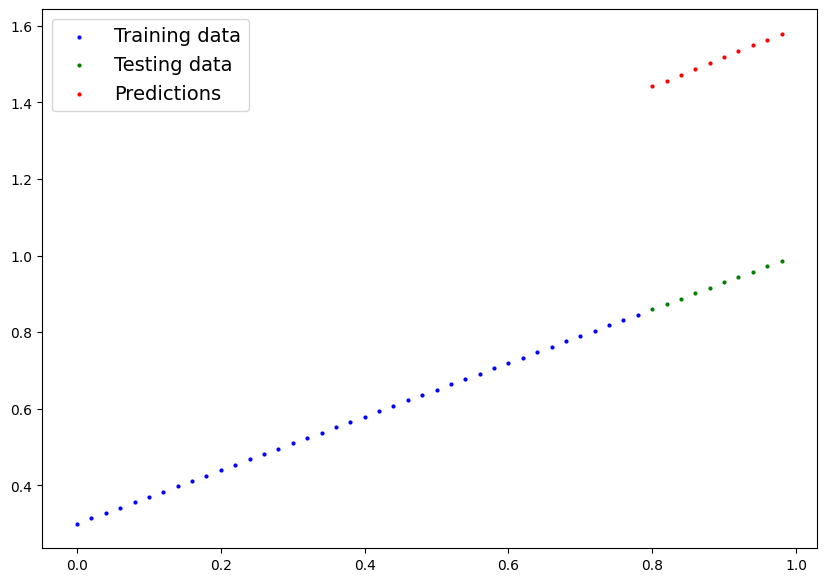

Text(0.5, 1.0, 'Predictions before training (red = random guesses)')

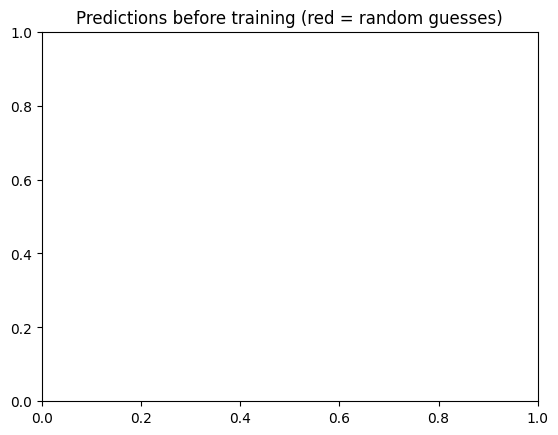

In [72]:
# See model's untrained predictions (on test set)
model_1.eval()

with torch.inference_mode():
    y_preds_early = model_1(X_test)

plot_predictions(predictions=y_preds_early)
plt.title("Predictions before training (red = random guesses)")

In [74]:
# Modelni va ma'lumotlarni bir xil qurilmaga ko'chirish
model_1 = model_1.to(device)

X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

# Model ko'chirilgandan keyin optimizatorni yaratish
optimizer = torch.optim.SGD(
    params=model_1.parameters(),
    lr=0.01
)

# Epochlar soni
epochs = 1000

for epoch in range(epochs):
    ### Training
    model_1.train()

    # 1. Bashorat qilish
    y_pred = model_1(X_train)

    # 2. Loss hisoblash
    loss = loss_fn(y_pred, y_train)

    # 3. Gradientlarni nolga tushirish
    optimizer.zero_grad()

    # 4. Backpropagation
    loss.backward()

    # 5. Model parametrlarini yangilash
    optimizer.step()

    ### Testing
    model_1.eval()

    with torch.inference_mode():
        test_pred = model_1(X_test)
        test_loss = loss_fn(test_pred, y_test)

    if epoch % 100 == 0:
        print(
            f"Epoch: {epoch} | "
            f"Train loss: {loss.item():.4f} | "
            f"Test loss: {test_loss.item():.4f}"
        )

Epoch: 0 | Train loss: 0.5552 | Test loss: 0.5740
Epoch: 100 | Train loss: 0.0062 | Test loss: 0.0141
Epoch: 200 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 300 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 400 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 500 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 600 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 700 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 800 | Train loss: 0.0013 | Test loss: 0.0138
Epoch: 900 | Train loss: 0.0013 | Test loss: 0.0138


In [75]:
# Turn model into evaluation mode
model_1.eval()

# Make predictions on the test data
with torch.inference_mode():
    y_preds = model_1(X_test)

y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]], device='cuda:0')

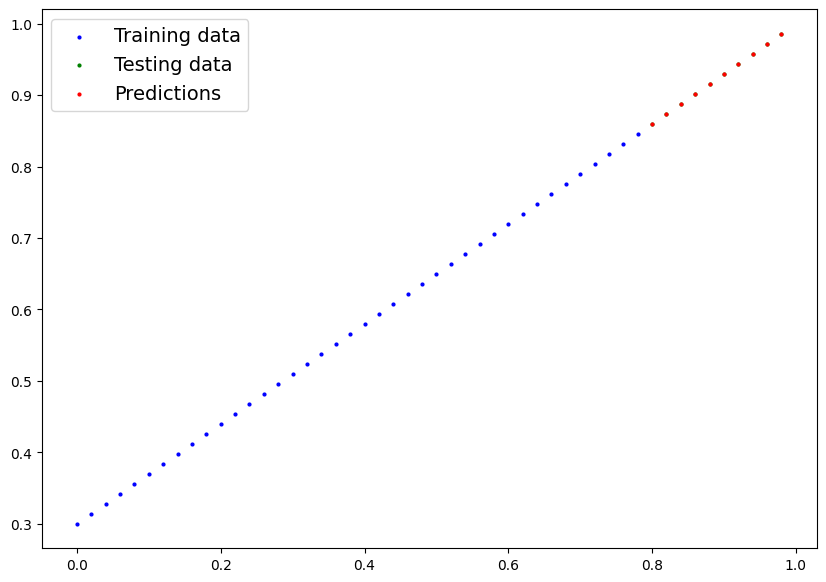

In [76]:
# Put data on the CPU and plot it
plot_predictions(predictions=y_preds.cpu())

In [77]:
torch.save(model_1.state_dict(), 'trained_model.pth')

In [78]:
loaded_model = LinearRegressionModelV2()
loaded_model.load_state_dict(torch.load('/content/trained_model.pth'))

loaded_model.eval()


LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)